# 03 · Pemodelan: Filter, Split, dan Membangun Setiap Model

Notebook ini membangun model satu per satu sesuai materi *Recommendation System*:

| # | Pendekatan | Model di proyek ini |
|---|---|---|
| 0 | Baseline | Popularitas (*weighted rating*) |
| 1 | **Rule-Based** | Association Rules — algoritma **Apriori** |
| 2 | **Content-Based** | TF-IDF (judul + penulis + penerbit) + cosine similarity |
| 3a | **Collaborative — memory-based** | Item-based CF (adjusted cosine) |
| 3b | **Collaborative — model-based** | Funk SVD (prediksi rating) dan PureSVD (peringkat Top-N) |
| 4 | **Hybrid** | Weighted + **Switching** → dibahas & dituning di notebook 04 |

Semua kode model ada di `src/models.py`; notebook ini menjelaskan cara kerjanya dan menunjukkan hasilnya.

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src import config as C, data_prep as D, models as M, evaluation as E

BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
plt.rcParams["axes.spines.top"] = plt.rcParams["axes.spines.right"] = False
pd.set_option("display.max_colwidth", 55)

books, users, ratings, summary = D.load_clean()

## 1. Filter dan split data

1. Ambil rating **eksplisit** (1–10).
2. Buku dengan ≥ 10 rating, lalu user dengan ≥ 3 rating (alasan: lihat EDA).
3. **Split per user**: tiap user menyisihkan ±20% ratingnya (minimal 1) sebagai **data uji**. Dengan begitu setiap user di data uji juga punya riwayat di data latih, sehingga rekomendasinya bisa dievaluasi.

In [2]:
model_df = D.build_model_data(ratings)
train, test = D.train_test_split_per_user(model_df)
index = D.Index.from_frame(train)
test = test[test["user_id"].isin(index.users)].reset_index(drop=True)

n_u, n_b = len(index.users), len(index.items)
print(f"Data model : {len(model_df):,} rating | {n_u:,} user | {n_b:,} buku")
print(f"Latih / uji: {len(train):,} / {len(test):,}")
print(f"Kekosongan matriks: {1 - len(model_df) / (n_u * n_b):.2%}")

Data model : 130,559 rating | 11,867 user | 5,656 buku
Latih / uji: 105,091 / 25,463
Kekosongan matriks: 99.81%


### Matriks utilitas

Semua metode bekerja di atas **matriks rating R** berukuran user × buku. Karena 99,8% isinya kosong, matriks disimpan dalam format **sparse** (hanya sel terisi yang disimpan).

In [3]:
R = M.build_matrix(train, index)
print(type(R).__name__, R.shape, f"- {R.nnz:,} sel terisi")
print(f"Memori sparse: {(R.data.nbytes + R.indices.nbytes + R.indptr.nbytes) / 1e6:.1f} MB "
      f"vs dense: {R.shape[0] * R.shape[1] * 8 / 1e6:.0f} MB")

catalog = books.set_index("book_id").loc[index.items].reset_index()   # urutan = kolom matriks
title = catalog["title"]

csr_matrix (11867, 5656) - 105,091 sel terisi
Memori sparse: 1.3 MB vs dense: 537 MB


## 2. Baseline: Popularitas (*weighted rating*)

Mengurutkan buku hanya dari rata-rata rating berbahaya: buku yang dinilai 10 oleh satu orang langsung di posisi teratas. Solusinya rumus *weighted rating* (dipakai IMDb):

$$WR_i = \frac{v_i}{v_i+m}\,\bar R_i + \frac{m}{v_i+m}\,C$$

- $v_i$ = jumlah rating buku $i$, $\bar R_i$ = rata-rata rating buku $i$
- $C$ = rata-rata rating semua buku, $m$ = "jumlah rating minimum yang dipercaya" (di sini median $v_i$)

Buku dengan sedikit rating "ditarik" ke $C$. Model ini **tidak personal** (semua user dapat daftar sama) dan dipakai untuk **user yang belum punya riwayat sama sekali**.

In [4]:
pop = M.PopularityRecommender().fit(R)
print(f"C = {pop.C:.3f},  m = {pop.m:.0f}")
top = np.argsort(-pop.wr)[:10]
pd.DataFrame({"judul": title[top].values, "jml rating": pop.count[top].astype(int),
              "rata-rata": pop.mean[top].round(2), "weighted rating": pop.wr[top].round(3)})

C = 7.800,  m = 11


,judul,jml rating,rata-rata,weighted rating
0,"The Two Towers (The Lord of the Rings, Part 2)",100,9.34,9.187
1,Harry Potter and the Goblet of Fire (Book 4),181,9.23,9.147
2,"The Return of the King (The Lord of the Rings, Part 3)",106,9.28,9.144
3,Harry Potter and the Chamber of Secrets Postcard Book,19,9.84,9.093
4,Harry Potter and the Order of the Phoenix (Book 5),147,9.14,9.043
5,The Giving Tree,20,9.70,9.026
6,Harry Potter and the Prisoner of Azkaban (Book 3),205,9.07,9.004
7,To Kill a Mockingbird,154,9.06,8.981
8,"The Fellowship of the Ring (The Lord of the Rings, ...",154,9.02,8.942
9,The Little Prince,62,9.13,8.929


## 3. Rule-Based: Association Rules (Apriori)

**Transaksi** = satu user; **item** = buku yang pernah ia baca (rating 0 ikut dihitung, karena yang penting "pernah membaca"). Untuk aturan $A \Rightarrow B$:

$$\text{support}(A\Rightarrow B) = P(A\cap B), \qquad \text{confidence} = P(B\mid A)=\frac{\text{support}(A\cap B)}{\text{support}(A)}, \qquad \text{lift}=\frac{\text{confidence}}{\text{support}(B)}$$

**Apriori** mencari *frequent itemset* level demi level. Prinsipnya: jika $\{A,B\}$ tidak sering muncul, maka $\{A,B,C\}$ pasti juga tidak, sehingga kandidat besar bisa dipangkas.

Agar komputasi ringan, hanya **300 buku paling sering dibaca** yang dipakai. Pasangan (user, buku) di data uji **dikeluarkan** agar evaluasi tidak bocor.

In [5]:
key = ratings["user_id"].astype(str) + "|" + ratings["book_id"]
test_key = set(test["user_id"].astype(str) + "|" + test["book_id"])
X, rule_items = M.build_transactions(ratings[~key.isin(test_key)])
print(f"{X.shape[0]:,} transaksi (user) x {X.shape[1]} buku")

freq = M.apriori(X, min_support=C.RULES_MIN_SUPPORT, max_len=3)
for k in (1, 2, 3):
    print(f"frequent itemset ukuran {k}: {sum(len(s) == k for s in freq):,}")
rules = M.association_rules(freq, min_confidence=C.RULES_MIN_CONFIDENCE)
print(f"aturan (confidence >= {C.RULES_MIN_CONFIDENCE}): {len(rules):,}")

11,084 transaksi (user) x 300 buku
frequent itemset ukuran 1: 300
frequent itemset ukuran 2: 3,146
frequent itemset ukuran 3: 430
aturan (confidence >= 0.2): 3,661


In [6]:
tl = books.set_index("book_id")["title"].str.slice(0, 40)
def nama(ids): return " + ".join(tl[rule_items[j]] for j in ids)
show = rules.sort_values("lift", ascending=False).head(10).copy()
show["jika membaca"] = show["antecedent"].map(nama)
show["maka rekomendasikan"] = show["consequent"].map(lambda c: tl[rule_items[c]])
show[["jika membaca", "maka rekomendasikan", "support", "confidence", "lift"]].round(3)

,jika membaca,maka rekomendasikan,support,confidence,lift
2714,Three To Get Deadly : A Stephanie Plum N + Seven Up...,High Five (A Stephanie Plum Novel),0.007,0.892,50.991
2522,Four To Score (A Stephanie Plum Novel) + Seven Up (...,High Five (A Stephanie Plum Novel),0.007,0.882,50.376
3398,Three To Get Deadly : A Stephanie Plum N + Hard Eig...,High Five (A Stephanie Plum Novel),0.006,0.829,47.379
2792,One for the Money (Stephanie Plum Novels + Seven Up...,High Five (A Stephanie Plum Novel),0.007,0.802,45.826
3113,Four To Score (A Stephanie Plum Novel) + Hard Eight...,High Five (A Stephanie Plum Novel),0.006,0.800,45.707
2687,Four To Score (A Stephanie Plum Novel) + Two for th...,High Five (A Stephanie Plum Novel),0.008,0.794,45.387
2597,Three To Get Deadly : A Stephanie Plum N + Seven Up...,Four To Score (A Stephanie Plum Novel),0.007,0.839,45.127
3537,Three To Get Deadly : A Stephanie Plum N + Four To ...,High Five (A Stephanie Plum Novel),0.009,0.787,44.958
3622,Seven Up (A Stephanie Plum Novel) + Two for the Dough,High Five (A Stephanie Plum Novel),0.007,0.781,44.636
3536,Three To Get Deadly : A Stephanie Plum N + High Fiv...,Four To Score (A Stephanie Plum Novel),0.009,0.828,44.529


Aturan dengan lift tertinggi hampir semuanya **buku dalam satu seri** (Stephanie Plum, Harry Potter, Lord of the Rings): jika membaca seri ke-3 dan ke-7, hampir pasti membaca seri ke-5.

> **Alternatif dengan library:** hasil yang sama bisa diperoleh dengan `mlxtend`:
> ```python
> from mlxtend.frequent_patterns import apriori, association_rules
> df_bool = pd.DataFrame(X.toarray().astype(bool), columns=rule_items)
> fi = apriori(df_bool, min_support=0.005, use_colnames=True, max_len=3)
> rules = association_rules(fi, metric="confidence", min_threshold=0.2)
> ```
> Di proyek ini Apriori ditulis sendiri (`M.apriori`) agar setiap langkahnya terlihat.

**Rule-based recommender:** untuk tiap user, jika semua buku di antecedent sudah dibaca, buku consequent diberi skor = confidence.

In [7]:
rule_rec = M.RuleRecommender().fit(rules, rule_items, index, pop)
contoh_user = index.users[np.argmax(np.diff(R.indptr) >= 30)]
hist_idx, hist_r = R[index.u2i[contoh_user]].indices, R[index.u2i[contoh_user]].data
rec = M.top_n(rule_rec.score_history(hist_idx), exclude=hist_idx, n=5)
print("User", contoh_user, "- contoh riwayat:", list(title[hist_idx[:5]]))
print("Rekomendasi rules:", list(title[rec]))

User 638 - contoh riwayat: ['The Saving Graces: A Novel', 'Love in the Time of Cholera (Penguin Great Books of the 20th Century)', 'The Lake House', 'The Lovely Bones: A Novel', 'Four Blind Mice']
Rekomendasi rules: ['The Return of the King (The Lord of the Rings, Part 3)', 'The Fellowship of the Ring (The Lord of the Rings, Part 1)', 'Divine Secrets of the Ya-Ya Sisterhood: A Novel', '1st to Die: A Novel', "She's Come Undone (Oprah's Book Club)"]


## 4. Content-Based: TF-IDF + cosine similarity

**Item profile.** Setiap buku diubah menjadi "dokumen": judul + token penulis + token penerbit. Penulis/penerbit dijadikan satu token utuh (misalnya `author_johngrisham`) agar namanya tidak terpecah, dan token penulis diulang dua kali supaya bobotnya lebih besar. Lalu dihitung **TF-IDF**:

$$w_{t,d} = \text{tf}_{t,d}\times\log\frac{N}{\text{df}_t}$$

Kata yang sering muncul di satu buku tetapi jarang di buku lain mendapat bobot besar.

**User profile.** Rata-rata tertimbang vektor buku yang **disukai** user (bobot = rating − rata-rata rating user, hanya yang positif). Skor rekomendasi = **cosine similarity** antara profil user dan setiap buku:

$$\cos(\mathbf p_u,\mathbf x_i)=\frac{\mathbf p_u\cdot\mathbf x_i}{\lVert\mathbf p_u\rVert\,\lVert\mathbf x_i\rVert}$$

In [8]:
cb = M.ContentBasedRecommender().fit(catalog, R)
print("Matriks TF-IDF:", cb.X.shape, "(buku x kata/token)")
i = int(np.where(title.str.startswith("The Da Vinci Code"))[0][0])
vocab = np.array(cb.vectorizer.get_feature_names_out())
row = cb.X[i].toarray().ravel()
print("Dokumen:", M.book_text(catalog.iloc[[i]]).iloc[0])
print("Bobot TF-IDF terbesar:", {vocab[j]: round(float(row[j]), 3) for j in np.argsort(-row)[:6] if row[j] > 0})

idx, sims = cb.similar_items(i, n=8)
pd.DataFrame({"buku mirip (Content-Based)": title[idx].values, "penulis": catalog["author"][idx].values, "cosine": sims.round(3)})

Matriks TF-IDF: (5656, 3413) (buku x kata/token)
Dokumen: The Da Vinci Code author_danbrown author_danbrown pub_doubleday
Bobot TF-IDF terbesar: {'author_danbrown': 0.63, 'vinci': 0.42, 'da': 0.42, 'code': 0.366, 'pub_doubleday': 0.341}


,buku mirip (Content-Based),penulis,cosine
0,El Codigo Da Vinci / The Da Vinci Code,Dan Brown,0.880
1,Illuminati.,Dan Brown,0.540
2,Deception Point,Dan Brown,0.474
3,Angels & Demons,Dan Brown,0.453
4,Digital Fortress : A Thriller,Dan Brown,0.447
5,Angels and Demons,Dan Brown,0.431
6,The Devil Wears Prada : A Novel,LAUREN WEISBERGER,0.225
7,The BIBLE CODE,Michael Drosnin,0.217


Content-Based memberi buku **penulis yang sama** atau judul serupa. Ini mudah dijelaskan dan bisa langsung bekerja untuk buku baru, tetapi kurang memberi kejutan (*filter bubble*). Fitur yang tersedia juga terbatas: dataset ini **tidak punya genre atau sinopsis**.

## 5. Collaborative Filtering — memory-based: Item-based CF

Dua buku dianggap mirip jika **dinilai serupa oleh user yang sama**. Kemiripan dihitung dengan **adjusted cosine**, yaitu cosine setelah setiap rating dikurangi rata-rata user-nya (*mean-centering*), sehingga kebiasaan user yang "pelit"/"royal" dinetralkan:

$$\text{sim}(i,j)=\frac{\sum_u (r_{ui}-\bar r_u)(r_{uj}-\bar r_u)}{\sqrt{\sum_u (r_{ui}-\bar r_u)^2}\sqrt{\sum_u (r_{uj}-\bar r_u)^2}}$$

Ditambah *shrinkage* $\frac{n_{ij}}{n_{ij}+10}$ agar kemiripan dari irisan user yang sedikit tidak terlalu dipercaya, dan hanya **50 tetangga terdekat** per buku yang disimpan.

**Prediksi rating** user $u$ untuk buku $i$ ($N(i)$ = tetangga $i$ yang sudah dinilai $u$):

$$\hat r_{ui}=\bar r_u+\frac{\sum_{j\in N(i)}\text{sim}(i,j)\,(r_{uj}-\bar r_u)}{\sum_{j\in N(i)}|\text{sim}(i,j)|}$$

### Contoh kecil (hitung manual)

In [9]:
toy = pd.DataFrame([[9, 8, np.nan, 3],
                    [8, np.nan, 9, 2],
                    [3, 2, 4, 9],
                    [np.nan, 9, 8, 3]],
                   index=["Ani", "Budi", "Citra", "Dodi"], columns=["Buku A", "Buku B", "Buku C", "Buku D"])
centered = toy.sub(toy.mean(axis=1), axis=0)           # mean-centering per user
def adj_cos(a, b):
    m = centered[[a, b]].dropna()
    return (m[a] * m[b]).sum() / np.sqrt((m[a] ** 2).sum() * (m[b] ** 2).sum())
print("Matriks rating:"); print(toy)
print("\nsim(A,B) =", round(adj_cos("Buku A", "Buku B"), 3), "| sim(A,C) =", round(adj_cos("Buku A", "Buku C"), 3),
      "| sim(A,D) =", round(adj_cos("Buku A", "Buku D"), 3))
# prediksi rating Dodi untuk Buku A, memakai tetangga B dan C (sim positif)
mu = toy.loc["Dodi"].mean()
nb = {"Buku B": adj_cos("Buku A", "Buku B"), "Buku C": adj_cos("Buku A", "Buku C")}
pred = mu + sum(s * (toy.loc["Dodi", j] - mu) for j, s in nb.items()) / sum(abs(s) for s in nb.values())
print(f"Prediksi rating Dodi untuk Buku A = {pred:.2f}  (rata-rata Dodi = {mu:.2f})")

Matriks rating:
       Buku A  Buku B  Buku C  Buku D
Ani       9.0     8.0     NaN       3
Budi      8.0     NaN     9.0       2
Citra     3.0     2.0     4.0       9
Dodi      NaN     9.0     8.0       3

sim(A,B) = 0.873 | sim(A,C) = 0.854 | sim(A,D) = -0.961
Prediksi rating Dodi untuk Buku A = 8.51  (rata-rata Dodi = 6.67)


Dodi menyukai B dan C (yang mirip dengan A), sehingga prediksi untuk A di atas rata-ratanya. Sekarang di data sebenarnya:

In [10]:
icf = M.ItemCFRecommender().fit(R)
print(f"Matriks kemiripan: {icf.S.shape}, {icf.S.nnz:,} pasangan tetangga tersimpan")
idx, sims = icf.similar_items(i, n=8)
pd.DataFrame({"buku mirip (Item-CF) untuk The Da Vinci Code": title[idx].values,
              "penulis": catalog["author"][idx].values, "kemiripan": sims.round(3)})

Matriks kemiripan: (5656, 5656), 272,770 pasangan tetangga tersimpan


,buku mirip (Item-CF) untuk The Da Vinci Code,penulis,kemiripan
0,The Secret Life of Bees,Sue Monk Kidd,0.044
1,"The Price of Loyalty: George W. Bush, the White Hou...",Ron Suskind,0.037
2,Bushwhacked : Life in George W. Bush's America,MOLLY IVINS,0.036
3,Angels & Demons,Dan Brown,0.034
4,The Red Tent (Bestselling Backlist),Anita Diamant,0.031
5,"My Sister's Keeper : A Novel (Picoult, Jodi)",Jodi Picoult,0.031
6,Harry Potter and the Order of the Phoenix (Book 5),J. K. Rowling,0.029
7,The Five People You Meet in Heaven,Mitch Albom,0.028


Berbeda dengan Content-Based, Item-CF menemukan buku **dari penulis lain** yang disukai pembaca yang sama (*serendipity*).

## 6. Collaborative Filtering — model-based: Matrix Factorization

### 6a. Funk SVD (untuk memprediksi **nilai** rating)

Matriks R didekomposisi menjadi faktor laten user ($\mathbf p_u$) dan buku ($\mathbf q_i$), plus bias:

$$\hat r_{ui}=\mu+b_u+b_i+\mathbf p_u^\top\mathbf q_i$$

Parameter dicari dengan **Stochastic Gradient Descent** yang meminimalkan galat kuadrat **hanya pada rating yang teramati**, ditambah regularisasi L2:

$$\min\sum_{(u,i)\in\text{teramati}}\left(r_{ui}-\hat r_{ui}\right)^2+\lambda\left(b_u^2+b_i^2+\lVert\mathbf p_u\rVert^2+\lVert\mathbf q_i\rVert^2\right)$$

Untuk tiap rating, galat $e_{ui}=r_{ui}-\hat r_{ui}$, lalu parameter diperbarui:
$b_u \leftarrow b_u+\eta(e_{ui}-\lambda b_u)$, $\;\mathbf p_u\leftarrow\mathbf p_u+\eta(e_{ui}\mathbf q_i-\lambda\mathbf p_u)$, dan seterusnya.

Bagi yang berlatar statistik: idenya mirip analisis faktor / PCA, yaitu rating dijelaskan oleh beberapa faktor tersembunyi. Bedanya, estimasi hanya memakai sel yang terisi.

**Tuning** jumlah faktor $k$ dan regularisasi $\lambda$ dilakukan di **data validasi** (sebagian data latih yang disisihkan), bukan di data uji:

In [11]:
tr2, va = D.train_test_split_per_user(train, seed=7)
idx2 = D.Index.from_frame(tr2)
va = va[va["user_id"].isin(idx2.users) & va["book_id"].isin(idx2.items)]
u2, i2 = idx2.encode(tr2); r2 = tr2["rating"].to_numpy(float)
vu, vi = idx2.encode(va); vr = va["rating"].to_numpy(float)

bias = M.BiasBaseline().fit(u2, i2, r2, len(idx2.users), len(idx2.items))
rows = [{"model": "baseline bias (k = 0)", "RMSE validasi": E.rmse(vr, bias.predict_many(vu, vi))}]
for k, reg in [(10, 0.05), (20, 0.15), (50, 0.15)]:
    m_ = M.FunkSVD(n_factors=k, reg=reg, n_epochs=30, lr=0.005).fit(u2, i2, r2, len(idx2.users), len(idx2.items))
    rows.append({"model": f"Funk SVD k={k}, lambda={reg}", "RMSE validasi": E.rmse(vr, m_.predict_many(vu, vi))})
pd.DataFrame(rows).round(4)

,model,RMSE validasi
0,baseline bias (k = 0),1.6160
1,"Funk SVD k=10, lambda=0.05",1.5995
2,"Funk SVD k=20, lambda=0.15",1.5923
3,"Funk SVD k=50, lambda=0.15",1.5957


Pipeline menjalankan grid yang lebih lengkap (k ∈ {10, 20, 50} × λ ∈ {0,05; 0,15}); terpilih **k = 20, λ = 0,15**. Faktor laten yang sedikit dan regularisasi yang kuat paling baik, karena datanya sangat jarang dan model besar mudah *overfitting*.

RMSE uji Funk SVD = 1.5577


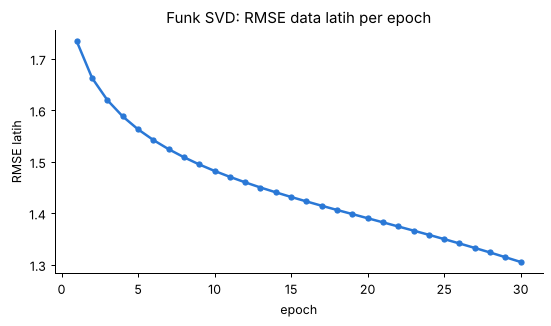

In [12]:
u, it = index.encode(train); r = train["rating"].to_numpy(float)
svd = M.FunkSVD(n_factors=20, reg=0.15, n_epochs=30, lr=0.005).fit(u, it, r, n_u, n_b, R=R)
tu, ti = index.encode(test); tr_ = test["rating"].to_numpy(float)
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(range(1, len(svd.history) + 1), svd.history, color=BLUE, lw=2, marker="o", ms=4)
ax.set(title="Funk SVD: RMSE data latih per epoch", xlabel="epoch", ylabel="RMSE latih")
print(f"RMSE uji Funk SVD = {E.rmse(tr_, svd.predict_many(tu, ti)):.4f}")

### 6b. Masalah: Funk SVD bagus untuk RMSE, tetapi tidak untuk Top-N

Jika rekomendasi disusun dari prediksi rating Funk SVD tertinggi, yang muncul justru buku *niche* dengan bias rating tinggi (sedikit pembaca, tetapi semuanya memberi 9–10). Model ini tidak pernah belajar **buku mana yang cenderung dibaca**, karena sel kosong diabaikan.

In [13]:
uu = index.u2i[contoh_user]
s_svd = svd.score_users(np.array([uu]))[0]
top_svd = M.top_n(s_svd, exclude=R[uu].indices, n=8)
pd.DataFrame({"Top-8 Funk SVD": title[top_svd].values, "jml rating buku": pop.count[top_svd].astype(int),
              "prediksi rating": np.clip(s_svd[top_svd], 1, 10).round(2)})

,Top-8 Funk SVD,jml rating buku,prediksi rating
0,"My Sister's Keeper : A Novel (Picoult, Jodi)",16,10.0
1,Harry Potter and the Chamber of Secrets Postcard Book,19,10.0
2,Dilbert: A Book of Postcards,10,10.0
3,Postmarked Yesteryear: 30 Rare Holiday Postcards,10,10.0
4,Weirdos From Another Planet!,19,10.0
5,Fox in Socks (I Can Read It All by Myself Beginner ...,9,10.0
6,Where the Sidewalk Ends : Poems and Drawings,16,10.0
7,Green Eggs and Ham (I Can Read It All by Myself Beg...,17,10.0


### 6c. PureSVD (untuk menyusun **peringkat** Top-N)

PureSVD (Cremonesi, Koren & Turrin, 2010) memakai **truncated SVD** biasa dengan sel kosong diisi 0:

$$R\approx U\Sigma V^\top \quad\Rightarrow\quad \text{skor}_u = \mathbf r_u V V^\top$$

Di sini sel kosong **diperlakukan sebagai sinyal**: buku yang tidak dibaca user mungkin memang kurang menarik baginya. Untuk tugas *ranking* hal ini justru membantu. Bonusnya, skor untuk **user baru** cukup dihitung dari vektor ratingnya ($\mathbf r_u V V^\top$) tanpa melatih ulang.

> Jadi ada dua SVD dengan tugas berbeda: **Funk SVD** → prediksi nilai rating (RMSE); **PureSVD** → peringkat Top-N. Pembuktiannya dengan angka ada di notebook 04.

In [14]:
psvd = M.PureSVDRecommender(50).fit(R)
s_ps = psvd.score_users(np.array([uu]))[0]
top_ps = M.top_n(s_ps, exclude=R[uu].indices, n=8)
pd.DataFrame({"Top-8 PureSVD": title[top_ps].values, "penulis": catalog["author"][top_ps].values,
              "jml rating buku": pop.count[top_ps].astype(int)})

,Top-8 PureSVD,penulis,jml rating buku
0,The Notebook,Nicholas Sparks,163
1,The Nanny Diaries: A Novel,Emma McLaughlin,210
2,White Oleander : A Novel (Oprah's Book Club),Janet Fitch,211
3,"The Fellowship of the Ring (The Lord of the Rings, ...",J.R.R. TOLKIEN,154
4,The Color Purple,Alice Walker,108
5,The Pilot's Wife : A Novel,Anita Shreve,167
6,The Clan of the Cave Bear (Earth's Children (Paperb...,Jean M. Auel,88
7,"The Return of the King (The Lord of the Rings, Part 3)",J.R.R. TOLKIEN,106


## 7. Hybrid: weighted + switching

**Weighted hybrid** menggabungkan dua skor setelah masing-masing dinormalisasi min-max ke 0–1 per user:

$$\text{skor}_{ui} = \alpha\cdot\widetilde{\text{CB}}_{ui} + (1-\alpha)\cdot\widetilde{\text{CF}}_{ui}$$

**Switching hybrid** memilih model berdasarkan banyaknya riwayat user $n_u$:

| kondisi | model |
|---|---|
| $n_u = 0$ | Popularitas |
| $1 \le n_u < \tau$ | weighted dengan $\alpha_\text{low}$ |
| $n_u \ge \tau$ | weighted dengan $\alpha_\text{high}$ |

Nilai $\tau$, $\alpha_\text{low}$, dan $\alpha_\text{high}$ **tidak ditebak**, tetapi dipilih dari data validasi di notebook 04.

In [15]:
contoh = M.SwitchingHybrid(pop, cb, psvd, threshold=20, alpha_low=0.4, alpha_high=0.2, R=R)
for n in [0, 3, 25]:
    print(f"n = {n:2d}:", contoh.choose(n)[1])

n =  0: Belum ada riwayat -> Popularitas (cold-start)
n =  3: Riwayat 3 buku (< 20) -> 40% Content-Based + 60% Collaborative (PureSVD)
n = 25: Riwayat 25 buku (>= 20) -> 20% Content-Based + 80% Collaborative (PureSVD)


Lanjut ke **04_Evaluasi_dan_Hybrid**.